# Notebook 4 - Customer segmentation with K-Means

> **Mentor briefing** - the seven questions we answer for every phase.

| Question | Answer |
|---|---|
| **1. What are we doing?** | Group customers who behave alike - without anyone telling the algorithm what the groups are - then give each group a business name. |
| **2. Why?** | Marketing cannot write 5,900 personal campaigns, but it can run 4-6 targeted ones. |
| **3. Real-world problem it solves** | Which customers deserve VIP treatment, which are slipping away, which have not yet become loyal? |
| **4. What does the code do?** | log1p -> StandardScaler -> K-Means for k=2..10, picks k with silhouette score, names clusters by matching them to business archetypes, projects to 2-D with PCA. |
| **5. Expected output** | A small number of segments (the data decides how many, up to 6), profile tables and six charts. |
| **6. What can go wrong?** | Forgetting to scale/log (one feature dominates); trusting the elbow blindly; naming clusters before looking at them; forcing six clusters the data does not contain. |
| **7. How do professionals approach this?** | They check cluster stability across random seeds, profile every cluster in original business units, and re-validate segments as new data arrives. |


## Concepts

* **Supervised learning** - learn from examples *with* an answer column (Notebook 5: "was the customer high value?"). **Unsupervised learning** - no answer column; find structure (this notebook).
* **K-Means** - pick *k* centre points; assign every customer to the nearest centre; move each centre to the average of its customers; repeat until nothing moves.
* **Centroid** - the centre of a cluster: the "average customer" of that group.
* **Inertia** - total squared distance from every customer to its centroid. Lower = tighter clusters. It *always* falls as k grows, so the **elbow method** looks for the k after which the improvement flattens.
* **Silhouette score** (-1..+1) - for each customer, compares "how close am I to my own cluster" with "how close am I to the next cluster". Near 1 = well separated; near 0 = overlapping; negative = probably in the wrong cluster.
* **PCA (Principal Component Analysis)** - squashes many dimensions into 2 that keep as much spread (variance) as possible, so we can *draw* the clusters. It is for plotting only; clustering happens in the full space.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                      # lets us import our own code from src/
from src.utils.config import get_paths, RANDOM_STATE
paths = get_paths(ROOT)

sns.set_theme(style="whitegrid", context="notebook", palette=["#2563eb", "#0d9488", "#4f46e5", "#eda100", "#eb6834", "#e87ba4"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (9, 4.2)})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 140
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from src.models.customer_segmentation import (SEGMENT_FEATURES, prepare_matrix, evaluate_k, choose_k, fit_segmentation, assign_segments, segment_profile, ARCHETYPES, SEGMENT_PLAYBOOK)
from src.utils.config import SEGMENT_COLORS
feats = pd.read_parquet(paths.processed / "customer_features.parquet")
print(f"{len(feats):,} customers; clustering on {SEGMENT_FEATURES}")

5,852 customers; clustering on ['recency_days', 'frequency', 'monetary']


## Steps 1-4: choose features, look at distributions, log-transform, scale

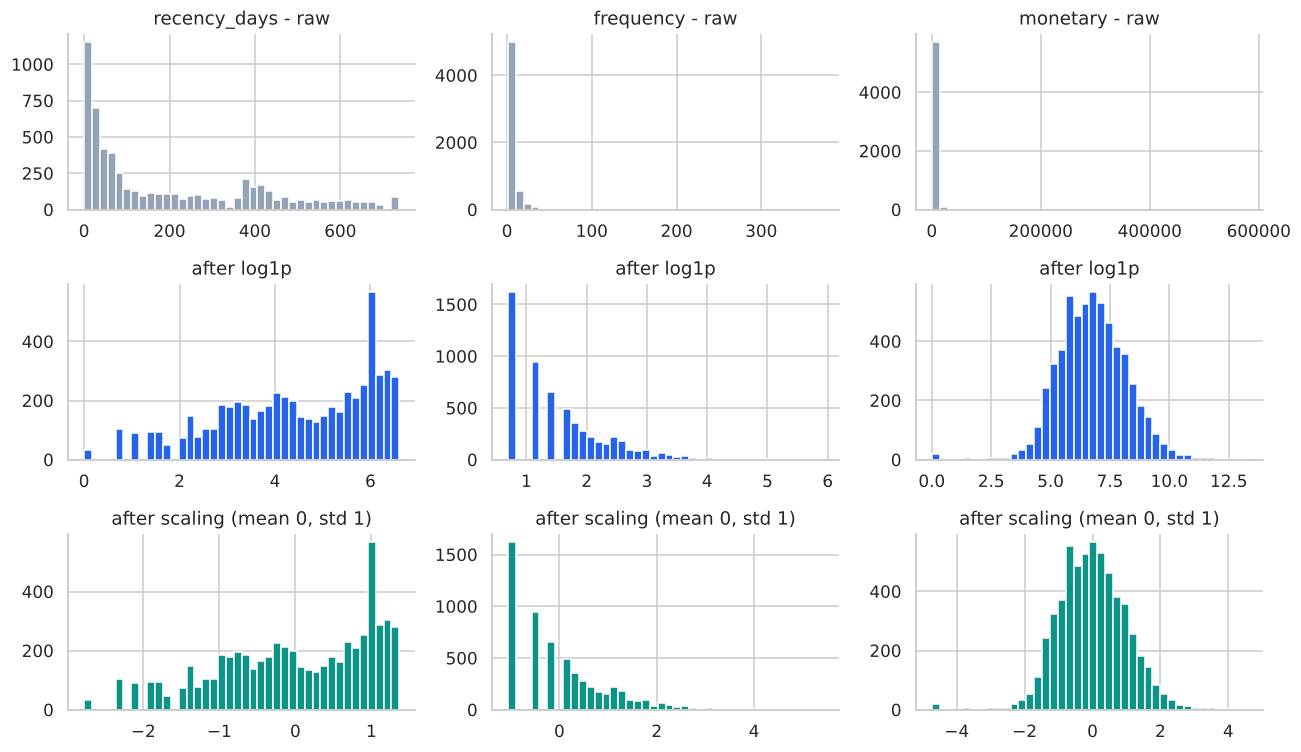

scaled means: [ 0.  0. -0.]  stds: [1. 1. 1.]


In [2]:
x_log = prepare_matrix(feats)
scaler = StandardScaler().fit(x_log); x = scaler.transform(x_log)
fig, ax = plt.subplots(3, 3, figsize=(12, 7))
for j, col in enumerate(SEGMENT_FEATURES):
    ax[0, j].hist(feats[col].clip(lower=0), bins=40, color="#94a3b8"); ax[0, j].set_title(f"{col} - raw")
    ax[1, j].hist(x_log[:, j], bins=40, color="#2563eb"); ax[1, j].set_title("after log1p")
    ax[2, j].hist(x[:, j], bins=40, color="#0d9488"); ax[2, j].set_title("after scaling (mean 0, std 1)")
plt.tight_layout(); plt.show()
print("scaled means:", x.mean(0).round(3), " stds:", x.std(0).round(3))

Why scale? K-Means measures **distance**. Frequency (1-200) and monetary (GBP 0-500,000) live on different scales; without scaling, money would decide everything. After `log1p` + `StandardScaler`, each feature has mean 0 and standard deviation 1 and counts equally.

## Steps 5-7: how many clusters? Elbow + silhouette

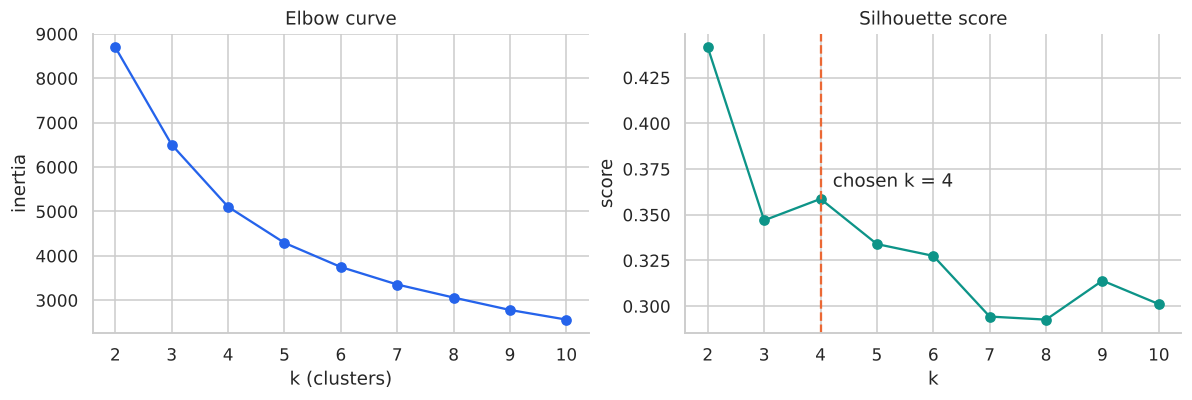

,k,inertia,silhouette
0,2,"8,697.91",0.44
1,3,"6,502.37",0.35
2,4,"5,104.92",0.36
3,5,"4,292.38",0.33
4,6,"3,748.20",0.33
5,7,"3,354.22",0.29
6,8,"3,060.24",0.29
7,9,"2,780.69",0.31
8,10,"2,563.49",0.30


In [3]:
metrics = evaluate_k(x)
best_k = choose_k(metrics)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(metrics.k, metrics.inertia, "o-", color="#2563eb"); ax[0].set(title="Elbow curve", xlabel="k (clusters)", ylabel="inertia")
ax[1].plot(metrics.k, metrics.silhouette, "o-", color="#0d9488"); ax[1].axvline(best_k, ls="--", color="#eb6834"); ax[1].set(title="Silhouette score", xlabel="k", ylabel="score")
ax[1].annotate(f"chosen k = {best_k}", (best_k, metrics.set_index("k").silhouette[best_k]), xytext=(8, 8), textcoords="offset points")
plt.tight_layout(); plt.show()
metrics.round(3)

**How we decide (documented rule in `choose_k`):** among k = 3..6 take the best silhouette; if a larger k is within 0.02 of it, prefer the larger k (a bit more actionable). We stop at 6 because we only have six business labels - and **we never force six**: if the data prefers fewer, we use fewer.

**Be honest about the numbers.** A silhouette around 0.3-0.4 means *moderately* separated groups. Real customers form a continuum (a smear, not islands). Segments are a **useful simplification**, not natural law.

## Steps 8-9: train K-Means and read the centroids

In [4]:
bundle = fit_segmentation(feats)
k = bundle["k"]; km = bundle["kmeans"]
print("chosen k:", k, "| silhouette:", round(bundle["silhouette"], 3), "| inertia:", round(km.inertia_, 1))
# centroids live in scaled-log space; undo the steps to read them in business units
centroids = np.expm1(bundle["scaler"].inverse_transform(km.cluster_centers_))
cent = pd.DataFrame(centroids, columns=SEGMENT_FEATURES).rename_axis("cluster")
cent["customers"] = np.bincount(km.labels_)
cent

chosen k: 4 | silhouette: 0.359 | inertia: 5104.4


,recency_days,frequency,monetary,customers
cluster,,,,
0,19.36,2.73,654.59,1234
1,328.67,1.31,229.60,1980
2,13.55,15.05,"5,635.77",1156
3,168.76,4.64,"1,496.86",1482


Each row is the "average customer" of a cluster (geometric-mean style, because we averaged in log space). Compare `recency_days`: a small number means the customers bought recently.

## Steps 10-11: profiles and business labels

In [5]:
seg = assign_segments(bundle, feats)
profile = segment_profile(feats, seg["segment"])
print("cluster -> label:", bundle["cluster_to_name"])
profile[["customers", "customer_share", "recency_median", "frequency_median", "monetary_median", "avg_order_value", "tenure_median", "revenue_share"]]

cluster -> label: {0: 'Potential Loyalists', 1: 'Hibernating Customers', 2: 'Champions', 3: 'At-Risk Customers'}


,customers,customer_share,recency_median,frequency_median,monetary_median,avg_order_value,tenure_median,revenue_share
segment,,,,,,,,
Champions,1156,0.20,16.00,13.00,"4,923.50",482.28,680.00,0.73
At-Risk Customers,1482,0.25,176.00,5.00,"1,443.45",470.11,618.00,0.17
Potential Loyalists,1234,0.21,23.00,3.00,711.57,312.05,218.00,0.06
Hibernating Customers,1980,0.34,400.00,1.00,263.44,251.67,438.50,0.04


**How labels are assigned (no hand-picking):** each business label has an *archetype* - target percentile scores for recency, frequency, monetary and tenure (e.g. Champions = very recent, very frequent, very high spend). We compare each cluster's median profile with every archetype and use the **Hungarian algorithm** to give each cluster the best *distinct* label. With 4 clusters, only the 4 best-fitting labels are used.

| Label | Archetype |
|---|---|
| Champions | recent, frequent, high spend |
| Loyal Customers | frequent, solid spend, fairly recent |
| Potential Loyalists | recent, only a few orders so far |
| New Customers | very recent *first* purchase, short tenure |
| At-Risk Customers | used to spend a lot, not seen for a long time |
| Hibernating Customers | low spend, long gone |

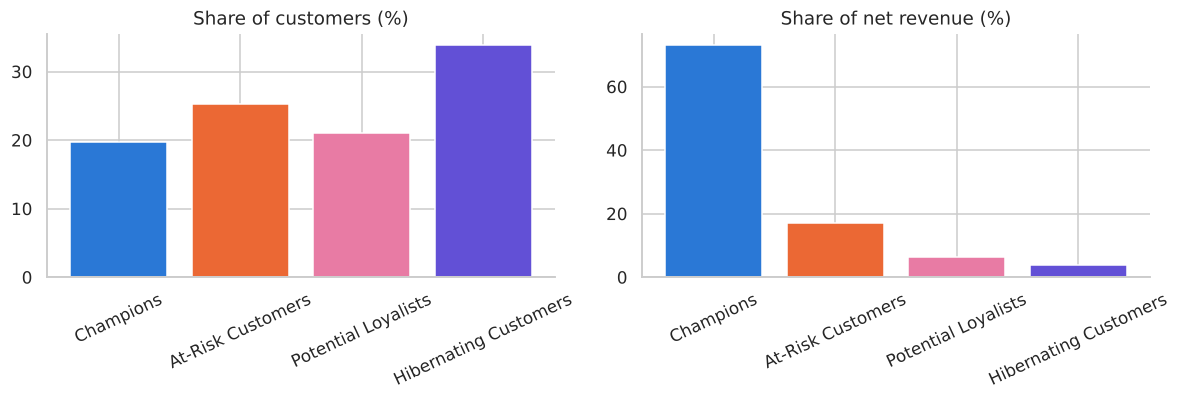

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
order = profile.sort_values("revenue_share", ascending=False).index
colors = [SEGMENT_COLORS.get(s, "#64748b") for s in order]
ax[0].bar(order, profile.loc[order, "customer_share"] * 100, color=colors); ax[0].set(title="Share of customers (%)"); ax[0].tick_params(axis="x", rotation=25)
ax[1].bar(order, profile.loc[order, "revenue_share"] * 100, color=colors); ax[1].set(title="Share of net revenue (%)"); ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

**Business reading.** Compare the two bars: the segment that is a small share of customers but a *large* share of revenue is where retention effort pays most; the segment that is a big share of customers but a tiny share of revenue needs cheap, automated treatment.

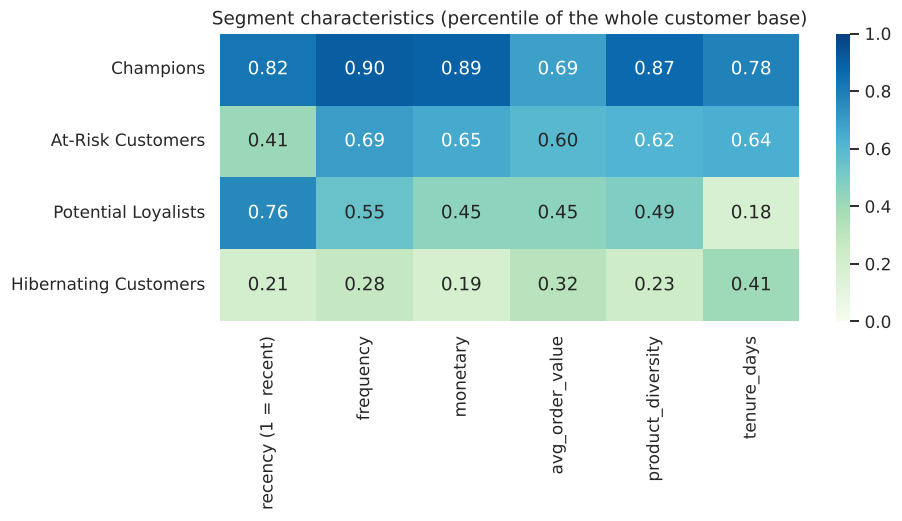

In [7]:
# Segment characteristics heatmap: each cell = percentile rank (0-1) of the segment's median vs ALL customers
cols = ["recency_days", "frequency", "monetary", "avg_order_value", "product_diversity", "tenure_days"]
med = feats.assign(segment=seg["segment"]).groupby("segment")[cols].median()
pct = pd.DataFrame({c: [(feats[c] <= v).mean() for v in med[c]] for c in cols}, index=med.index)
pct["recency_days"] = 1 - pct["recency_days"]                # flip: 1 = bought very recently
pct = pct.rename(columns={"recency_days": "recency (1 = recent)"}).loc[order]
fig, ax = plt.subplots(figsize=(8.5, 3.4)); sns.heatmap(pct, annot=True, fmt=".2f", cmap="GnBu", vmin=0, vmax=1, ax=ax)
ax.set(title="Segment characteristics (percentile of the whole customer base)", ylabel=""); plt.show()

## PCA: draw the clusters in 2-D

variance explained by the 2 components: [0.757 0.189] -> total 0.946


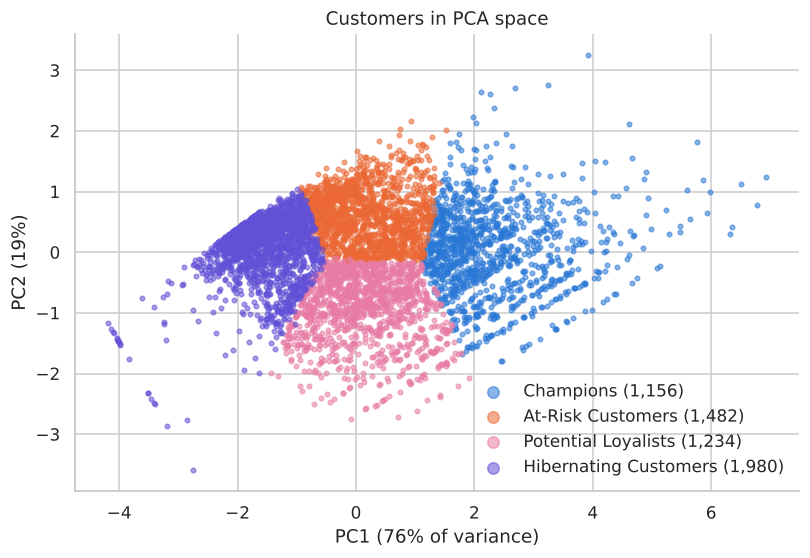

,recency_days,frequency,monetary
PC1,-0.51,0.62,0.60
PC2,0.86,0.28,0.43


In [8]:
pca = bundle["pca"]
print("variance explained by the 2 components:", pca.explained_variance_ratio_.round(3), "-> total", pca.explained_variance_ratio_.sum().round(3))
fig, ax = plt.subplots(figsize=(8.5, 5.4))
for s in order:
    m = seg["segment"] == s
    ax.scatter(seg.loc[m, "pc1"], seg.loc[m, "pc2"], s=9, alpha=.55, color=SEGMENT_COLORS.get(s, "#64748b"), label=f"{s} ({m.sum():,})")
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})", title="Customers in PCA space")
ax.legend(markerscale=2.5, frameon=False); plt.show()
pd.DataFrame(pca.components_, columns=SEGMENT_FEATURES, index=["PC1", "PC2"]).round(2)

The loadings table says what each axis *means* (e.g. a PC that weights frequency and monetary positively and recency negatively is a "how valuable" axis). Because the groups touch, you see the continuum mentioned earlier.

## Silhouette analysis (per customer)

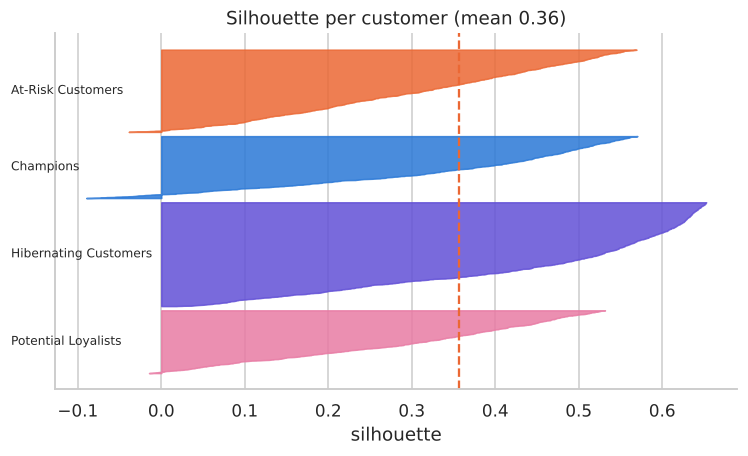

customers with a NEGATIVE silhouette (probably borderline): 2.1%


In [9]:
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(x), min(3000, len(x)), replace=False)
sil = silhouette_samples(x[idx], km.labels_[idx])
fig, ax = plt.subplots(figsize=(8, 4.2)); y0 = 0
for c in range(k):
    v = np.sort(sil[km.labels_[idx] == c]); name = bundle["cluster_to_name"][c]
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=SEGMENT_COLORS.get(name, "#64748b"), alpha=.85); ax.text(-0.18, y0 + len(v) / 2, name, va="center", fontsize=8); y0 += len(v) + 40
ax.axvline(sil.mean(), color="#eb6834", ls="--"); ax.set(title=f"Silhouette per customer (mean {sil.mean():.2f})", xlabel="silhouette", yticks=[]); plt.show()
print("customers with a NEGATIVE silhouette (probably borderline):", f"{(sil < 0).mean():.1%}")

## Is the result stable? (what professionals check)
K-Means starts from random centres. If a different seed gives a very different answer, the segments are not trustworthy. **Adjusted Rand Index (ARI)** = 1 means identical groupings.

In [10]:
ari = [adjusted_rand_score(km.labels_, KMeans(n_clusters=k, n_init=10, random_state=s).fit(x).labels_) for s in range(1, 6)]
print("ARI vs the final model across 5 other seeds:", np.round(ari, 3))

ARI vs the final model across 5 other seeds: [0.967 0.991 1.    0.999 1.   ]


In [11]:
import joblib
saved = joblib.load(paths.models / "kmeans_customer_segments.joblib")
assert saved["k"] == k and (assign_segments(saved, feats)["cluster"] == seg["cluster"]).all()
print("Saved model models/kmeans_customer_segments.joblib reproduces these segments exactly.")
for s in order: print(f"\n{s}: {SEGMENT_PLAYBOOK[s]['who']}\n   -> {SEGMENT_PLAYBOOK[s]['action']}")

Saved model models/kmeans_customer_segments.joblib reproduces these segments exactly.

Champions: Buy often, spend the most, bought very recently.
   -> Reward and recruit: early access, loyalty perks, referral asks. Avoid discounting - they already buy.

At-Risk Customers: Used to spend a lot but have gone quiet.
   -> Win-back now: personalised outreach, 'we miss you' offer, ask for feedback.

Potential Loyalists: Recent buyers with moderate frequency and spend.
   -> Nudge a second and third order: replenishment reminders and product-affinity emails.

Hibernating Customers: Low spend, long inactive.
   -> Low-cost reactivation only (one email wave); suppress from paid campaigns afterwards.


## Check yourself
1. Why would K-Means without scaling produce a "money only" clustering?
2. The elbow is not obvious here. Which second tool do we use, and what does a score of 0.35 mean?
3. If the data supports only 4 clusters, why is that *better* than forcing six?